# Project 12: Model Calibration Lab

**Original statement (verbatim from LAB_Projects_ML.pdf):**

A classifier outputs probabilities. Task: Assess calibration; Apply Platt scaling and isotonic regression; Measure calibration improvement quantitatively

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Good probabilities should match observed frequencies: a model that says 80% should be right about 80% of the time. This notebook measures that gap before and after calibration.

## Part 1 — Introduction

Calibration is measured for the 4-class weather label using confidence (max predicted probability) bins and multiclass Brier/log-loss. Platt scaling is sigmoid calibration and isotonic is isotonic calibration, both via CalibratedClassifierCV.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Calibration metrics

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
def ece(y_true, proba, n_bins=10):
    conf=proba.max(axis=1); pred=proba.argmax(axis=1); bins=np.linspace(0,1,n_bins+1); total=0.0
    for i in range(n_bins):
        m=(conf>bins[i])&(conf<=bins[i+1]) if i>0 else (conf>=bins[i])&(conf<=bins[i+1])
        if m.sum()>0: total+=abs(np.mean(pred[m]==y_true[m])-np.mean(conf[m]))*m.mean()
    return float(total)
def brier_multi(y_true, proba):
    Y=np.zeros_like(proba); Y[np.arange(len(y_true)), y_true]=1; return float(np.mean(np.sum((proba-Y)**2, axis=1)))
df=df_full.sample(n=25000, random_state=42)
Xtr,Xtemp,ytr,ytemp=train_test_split(df[FEATURES], df[TARGET], test_size=0.4, random_state=42, stratify=df[TARGET])
Xcal,Xte,ycal,yte=train_test_split(Xtemp, ytemp, test_size=0.5, random_state=42, stratify=ytemp)
base_models={
 "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
 "RandomForest": RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1),
}
for name, m in base_models.items():
    m.fit(Xtr,ytr); p=m.predict_proba(Xte); print(name, "uncalibrated: accuracy", round(accuracy_score(yte, m.predict(Xte)),4), "logloss", round(log_loss(yte,p),4), "multiclass Brier", round(brier_multi(yte.values,p),4), "ECE", round(ece(yte.values,p),4))

LogisticRegression uncalibrated: accuracy 0.7924 logloss 0.4698 multiclass Brier 0.2947 ECE 0.0181


RandomForest uncalibrated: accuracy 0.8884 logloss 0.3073 multiclass Brier 0.1799 ECE 0.0688


## Part 4 — Platt and isotonic calibration

LogisticRegression sigmoid : accuracy 0.6036 logloss 0.775 Brier 0.4699 ECE 0.076


LogisticRegression isotonic : accuracy 0.6512 logloss 0.6827 Brier 0.438 ECE 0.0935


RandomForest sigmoid : accuracy 0.8224 logloss 0.45 Brier 0.2588 ECE 0.0154


RandomForest isotonic : accuracy 0.8182 logloss 0.4318 Brier 0.2599 ECE 0.0128


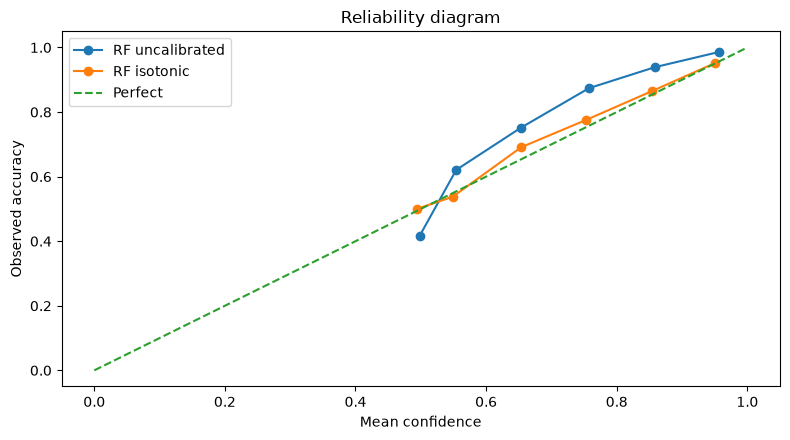

In [3]:
for name, m in base_models.items():
    for method in ["sigmoid","isotonic"]:
        cal=CalibratedClassifierCV(m, method=method, cv=3); cal.fit(Xcal,ycal); p=cal.predict_proba(Xte); print(name, method, ": accuracy", round(accuracy_score(yte, cal.predict(Xte)),4), "logloss", round(log_loss(yte,p),4), "Brier", round(brier_multi(yte.values,p),4), "ECE", round(ece(yte.values,p),4))
# Reliability plot for RandomForest uncalibrated vs isotonic
import math
rf=base_models["RandomForest"]; cal_iso=CalibratedClassifierCV(rf, method="isotonic", cv=3); cal_iso.fit(Xcal,ycal)
for label, proba in [("RF uncalibrated", rf.predict_proba(Xte)), ("RF isotonic", cal_iso.predict_proba(Xte))]:
    conf=proba.max(axis=1); pred=proba.argmax(axis=1); bins=np.linspace(0,1,11); xs=[]; ys=[]
    for i in range(10):
        mm=(conf>bins[i])&(conf<=bins[i+1]) if i>0 else (conf>=bins[i])&(conf<=bins[i+1])
        if mm.sum()>0: xs.append(np.mean(conf[mm])); ys.append(np.mean(pred[mm]==yte.values[mm]))
    plt.plot(xs,ys,marker="o",label=label)
plt.plot([0,1],[0,1],"--",label="Perfect"); plt.xlabel("Mean confidence"); plt.ylabel("Observed accuracy"); plt.title("Reliability diagram"); plt.legend(); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: Calibration improves when log-loss, Brier score and ECE fall without a large accuracy loss. Isotonic is more flexible but needs more calibration data and can overfit small calibration sets; sigmoid (Platt) is safer when data are scarce. Choose from the table above, not from intuition.")

INTERPRETATION: Calibration improves when log-loss, Brier score and ECE fall without a large accuracy loss. Isotonic is more flexible but needs more calibration data and can overfit small calibration sets; sigmoid (Platt) is safer when data are scarce. Choose from the table above, not from intuition.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.